<a href="https://colab.research.google.com/github/Felipemp20/Proyecto-Modelos-ll/blob/main/02_modelos_rev01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PrediCasa – Entregable II: Entrenamiento y evaluación de modelos
**Modelos y Simulación de Sistemas II – Universidad de Antioquia**

Este notebook continúa el análisis exploratorio de `PrediCasa.ipynb` (Entregable I). Aquí se construye la configuración experimental:

1. Carga de datos y eliminación de los dos valores atípicos.
2. Partición  **80/20** (train/test) estratificada por el precio.
3. **Pipeline** de preprocesamiento (imputación + codificación + escalado) que se ajusta solo con los datos de entrenamiento de cada pliegue, para evitar fuga de información.
4. Funciones de evaluación con validación cruzada de 5 pliegues, métricas en escala original (dólares) e intervalos de confianza.
5. Prueba del pipeline con un modelo base.

---
Configuración del entorno. Clonar el repositorio para que `data/train.csv` se lea con la misma ruta que en GitHub

In [3]:
import os, subprocess

REPO_URL = "https://github.com/Felipemp20/Proyecto-Modelos-ll.git"
REPO_DIR = "Proyecto-Modelos-ll"

if not os.path.exists("data/train.csv"):
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(REPO_DIR)

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/Proyecto-Modelos-ll


Importar librerías y definición de la semilla (`SEED = 42`) para que todos los resultados sean reproducibles. También se crean las carpetas `figures/` y `results/`, donde se guardarán las gráficas y las tablas de resultados.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
import joblib, time, warnings
warnings.filterwarnings("ignore")  # oculta avisos de convergencia durante la búsqueda en malla

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

SEED = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 1. Carga de datos
Se lee `train.csv` igual que en el Entregable I: el texto `NA` se marca como nulo, pero valores como `None` (p. ej. en `MasVnrType`) se conservan como categoría.

Lectura del archivo y verificación de dimensiones.

In [5]:
df = pd.read_csv("data/train.csv", keep_default_na=False, na_values=["NA", ""])
print("Dimensiones:", df.shape)

Dimensiones: (1460, 81)


Eliminación de los dos valores atípicos identificados en el Entregable I (Id 524 y 1299: más de 4000 pies² habitables, calidad 10 y precio menor a USD 185 000). Se eliminan antes de la partición para que no afecten ni el entrenamiento ni la evaluación. Después se separan la variable objetivo `y` (`SalePrice`) y los predictores `X` (sin `Id`, que no aporta información y podría generar fuga).

In [7]:
atipicos = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print("Atípicos eliminados (Id):", atipicos["Id"].tolist())
df = df.drop(index=atipicos.index).reset_index(drop=True)

y = df["SalePrice"]
X = df.drop(columns=["Id", "SalePrice"])
print("X:", X.shape, "| y:", y.shape)

Atípicos eliminados (Id): []
X: (1458, 79) | y: (1458,)


## 2. Partición train/test (80/20)
El conjunto de prueba de Kaggle no tiene `SalePrice`, así que se reserva el **20 %** de las viviendas para test. Ese test no se toca hasta la evaluación final de cada modelo.

La partición se estratifica por deciles del precio para que train y test tengan la misma distribución de casas baratas y caras.

Partición y comparación de las estadísticas del precio en ambos conjuntos.

In [8]:
deciles = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=deciles, random_state=SEED)

print(f"Train: {X_train.shape[0]} viviendas | Test: {X_test.shape[0]} viviendas")
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(0)

Train: 1166 viviendas | Test: 292 viviendas


,train,test
count,1166.0,292.0
mean,180985.0,180724.0
std,79353.0,80196.0
min,34900.0,35311.0
25%,129925.0,129750.0
50%,162950.0,163495.0
75%,213875.0,214875.0
max,755000.0,625000.0


## 3. Preprocesamiento dentro de un Pipeline
En el Entregable I la imputación se calculó con todas las filas. El preprocesamiento se implementa como un transformador de scikit-learn que aprende sus estadísticas solo con los datos de entrenamiento (en la validación cruzada, solo con los pliegues de entrenamiento).

Cambios respecto al Entregable I:
- `GarageYrBlt` ya **no se imputa con 0** (el año 0 distorsiona los modelos lineales, la SVM y la red). Las casas sin garaje toman el año de construcción de la vivienda (`YearBuilt`).
- `LotFrontage` se imputa con la mediana por barrio **calculada en train**.

Definición de la clase `PreprocesadorAmes`, que aplica las reglas del dominio (NA = ausencia, imputaciones, variables numéricas que son categóricas y codificación ordinal de las variables de calidad).

In [9]:
NONE_COLS = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
ZERO_COLS = ["GarageArea", "GarageCars", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
             "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]
NUM_A_CAT = ["MSSubClass", "MoSold", "YrSold"]
ORD_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
            "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
ESCALA = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}


class PreprocesadorAmes(BaseEstimator, TransformerMixin):
    # Reglas de dominio del dataset Ames. Las estadísticas (medianas por barrio)
    # se aprenden en fit() solo con los datos de entrenamiento.

    def __init__(self, ordinal_como_entero=True):
        self.ordinal_como_entero = ordinal_como_entero

    def fit(self, X, y=None):
        self.mediana_barrio_ = X.groupby("Neighborhood")["LotFrontage"].median()
        self.mediana_lot_ = X["LotFrontage"].median()
        return self

    def transform(self, X):
        X = X.copy()
        for c in NONE_COLS:
            X[c] = X[c].fillna("None")
        for c in ZERO_COLS:
            X[c] = X[c].fillna(0)
        X["GarageYrBlt"] = X["GarageYrBlt"].fillna(X["YearBuilt"])
        X["LotFrontage"] = (X["LotFrontage"]
                            .fillna(X["Neighborhood"].map(self.mediana_barrio_))
                            .fillna(self.mediana_lot_))
        for c in NUM_A_CAT:
            X[c] = X[c].astype(str)
        if self.ordinal_como_entero:
            for c in ORD_COLS:
                X[c] = X[c].map(ESCALA).astype(float)
        return X

La función `crear_pipeline(modelo)`, es la que arma el flujo completo para cualquier modelo:

1. `PreprocesadorAmes` (reglas del dominio).
2. `ColumnTransformer`:
   - **numéricas:** imputación con la mediana (por si queda algún nulo) y estandarización (`StandardScaler`) cuando `escalar=True`. Los modelos de árboles no la necesitan, pero la regresión regularizada, la SVR y la red sí.
   - **nominales:** imputación con la moda (p. ej. `Electrical`) y **one-hot**. `handle_unknown="ignore"` evita errores si en un pliegue aparece una categoría que no estaba en entrenamiento.
3. El modelo, envuelto en `TransformedTargetRegressor`: entrena con `log(1 + SalePrice)` (y además lo estandariza) pero **devuelve las predicciones en dólares**. Así MAE y RMSE quedan en escala original, y el RMSLE se calcula aparte.

In [10]:
def crear_pipeline(modelo, escalar=True, ordinal_como_entero=True):
    paso_num = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        paso_num.append(("esc", StandardScaler()))

    columnas = ColumnTransformer([
        ("num", Pipeline(paso_num), make_column_selector(dtype_include="number")),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), make_column_selector(dtype_include="object")),
    ])

    # Transformación del objetivo: log(1 + y) y luego estandarización
    transf_y = Pipeline([
        ("log", FunctionTransformer(np.log1p, inverse_func=np.expm1, check_inverse=False)),
        ("esc", StandardScaler()),
    ])
    regresor = TransformedTargetRegressor(regressor=modelo, transformer=transf_y)

    return Pipeline([
        ("prep", PreprocesadorAmes(ordinal_como_entero=ordinal_como_entero)),
        ("cols", columnas),
        ("modelo", regresor),
    ])

Comprobación rápida del preprocesamiento. Se ajusta solo con `X_train` y se verifica que no queden nulos y cuántos predictores resultan tras el one-hot (en el Entregable I eran 255 con `drop_first=True`; aquí son algunos más porque se conservan todas las categorías, lo que no afecta a los modelos regularizados).

In [11]:
prep = crear_pipeline(Ridge()).steps[:2]
prep = Pipeline(prep).fit(X_train)
Xt = prep.transform(X_train)
print("Matriz de entrenamiento transformada:", Xt.shape)
print("Nulos restantes:", int(np.isnan(Xt).sum()))
print(f"Razón muestras/predictores: {Xt.shape[0] / Xt.shape[1]:.1f}")

Matriz de entrenamiento transformada: (1166, 287)
Nulos restantes: 0
Razón muestras/predictores: 4.1


## 4. Métricas e intervalos de confianza
Métricas usadas (todas sobre predicciones en **dólares**):

- **RMSLE** (métrica principal, la de Kaggle): $\sqrt{\frac{1}{n}\sum_i (\log(1+\hat y_i) - \log(1+y_i))^2}$. Mide el error relativo, así que una casa barata pesa igual que una cara.
- **RMSE** y **MAE** en USD: error típico en dólares.
- **R²**: proporción de la varianza del precio explicada por el modelo.

**Intervalos de confianza al 95 %**: con $k = 5$ pliegues se usa la distribución t de Student:
$\bar{x} \pm t_{0.975,\,k-1}\,\frac{s}{\sqrt{k}}$.

Definición de los *scorers* de scikit-learn para estas cuatro métricas y del esquema de validación cruzada (`KFold` de 5 pliegues con la semilla fija, para que **todos los modelos se evalúen con exactamente los mismos pliegues**).

In [12]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)  # evita log de valores negativos
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

SCORERS = {
    "RMSLE": make_scorer(rmsle, greater_is_better=False),
    "RMSE": make_scorer(rmse, greater_is_better=False),
    "MAE": make_scorer(mean_absolute_error, greater_is_better=False),
    "R2": make_scorer(r2_score),
}

CV = KFold(n_splits=5, shuffle=True, random_state=SEED)

Función `evaluar_cv(pipeline, nombre)`. Ejecuta la validación cruzada sobre **train** y devuelve, para cada métrica, la media y el intervalo de confianza del 95 % tanto en **entrenamiento** como en **validación**. Comparar ambas columnas permite detectar sobreajuste (train mucho mejor que validación) o subajuste (ambas malas).

In [13]:
def intervalo(valores, conf=0.95):
    valores = np.asarray(valores)
    k = len(valores)
    media = valores.mean()
    margen = stats.t.ppf((1 + conf) / 2, k - 1) * valores.std(ddof=1) / np.sqrt(k)
    return media, margen


def evaluar_cv(pipeline, nombre):
    res = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=SCORERS,
                         return_train_score=True, n_jobs=-1)
    fila = {"modelo": nombre}
    for m in SCORERS:
        signo = -1 if m != "R2" else 1  # sklearn devuelve errores en negativo
        for fase, clave in [("train", f"train_{m}"), ("val", f"test_{m}")]:
            media, margen = intervalo(signo * res[clave])
            fila[f"{m}_{fase}"] = media
            fila[f"{m}_{fase}_IC"] = margen
    return fila


def mostrar(filas):
    # Tabla legible: "media ± margen" para cada métrica y fase
    tabla = pd.DataFrame(filas).set_index("modelo")
    salida = pd.DataFrame(index=tabla.index)
    formatos = {"RMSLE": "{:.4f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}"}
    for m, f in formatos.items():
        for fase in ["train", "val"]:
            salida[f"{m} {fase}"] = [f"{f.format(a)} ± {f.format(b)}"
                                     for a, b in zip(tabla[f"{m}_{fase}"], tabla[f"{m}_{fase}_IC"])]
    return salida

## 5. Prueba del pipeline con un modelo base
Antes de la búsqueda de hiperparámetros se comprueba que todo funcione con una **regresión Ridge** con valores por defecto (`alpha = 1`). Esta prueba sirve como referencia y para verificar que las métricas tengan valores razonables (en la literatura sobre Ames, el RMSLE de modelos lineales regularizados ronda 0.11–0.13).

Validación cruzada del modelo base y tabla con las métricas de entrenamiento y validación con sus intervalos de confianza.

In [14]:
base = evaluar_cv(crear_pipeline(Ridge(alpha=1.0)), "Ridge (base, alpha=1)")
mostrar([base])

,RMSLE train,RMSLE val,RMSE train,RMSE val,MAE train,MAE val,R2 train,R2 val
modelo,,,,,,,,
"Ridge (base, alpha=1)",0.0871 ± 0.0033,0.1245 ± 0.0197,"15,824 ± 615","24,315 ± 6,288","10,872 ± 345","15,409 ± 2,166",0.960 ± 0.004,0.900 ± 0.054


Se guarda el resultado del modelo base en `results/` para no tener que recalcularlo.

In [15]:
pd.DataFrame([base]).to_csv("results/cv_modelo_base.csv", index=False)
print("Guardado en results/cv_modelo_base.csv")

Guardado en results/cv_modelo_base.csv


---
# Entrenamiento y evaluación de los modelos

Se compararan **seis modelos**: los cinco requeridos y ademas Random Forest, que servirá para contrastar los dos tipos de ensamble (bagging y boosting).

| Requisito de la guía | Modelo | ¿Escalado? |
|---|---|---|
| Paramétrico (regresión) | ElasticNet (Ridge + Lasso) | Sí |
| No paramétrico | Árbol de decisión | No |
| Ensamble de árboles (bagging) | Random Forest | No |
| Ensamble de árboles (boosting) | XGBoost | No |
| Red neuronal artificial | MLPRegressor | Sí |
| Máquina de vectores de soporte | SVR (kernel RBF) | Sí |

Para cada modelo se hace lo mismo:
1. **Búsqueda en malla** (`GridSearchCV`) con los mismos 5 pliegues sobre train. Se guardan las métricas de entrenamiento y validación de **todas** las combinaciones.
2. **Gráficas y tablas** del efecto de los hiperparámetros.
3. La mejor configuración (menor RMSLE de validación) se reentrena con todo train y se evalúa **una sola vez en test**.

Con el parámetro `RECALCULAR` cada resultado se guarda en `results/`; si `RECALCULAR = False` y el archivo ya existe, se carga en lugar de volver a entrenar.

In [16]:
RECALCULAR = False
os.environ["PYTHONWARNINGS"] = "ignore"  # también oculta avisos en los procesos paralelos

La función `buscar(...)`. Recibe el modelo y su malla de valores, ejecuta `GridSearchCV` con las cuatro métricas (selecciona por RMSLE) y guarda dos archivos:
- `results/grid_<modelo>.csv` (y `.pkl`): resultados de todas las combinaciones (para las gráficas y tablas).
- `results/best_<modelo>.pkl`: los mejores hiperparámetros (para reentrenar sin repetir la búsqueda).

Devuelve la tabla de resultados y el pipeline con la mejor configuración, ya entrenado con todo train.

In [17]:
def buscar(clave, modelo, malla, escalar=True, malla_extra=None):
    ruta_res = f"results/grid_{clave}.csv"
    ruta_best = f"results/best_{clave}.pkl"
    pipe = crear_pipeline(modelo, escalar=escalar)

    ruta_pkl = f"results/grid_{clave}.pkl"
    if not RECALCULAR and os.path.exists(ruta_pkl) and os.path.exists(ruta_best):
        res = pd.read_pickle(ruta_pkl)
        mejores = joblib.load(ruta_best)
        print(f"[{clave}] resultados cargados de {ruta_pkl}")
    else:
        grid = {f"modelo__regressor__{k}": v for k, v in malla.items()}
        if malla_extra:
            grid.update(malla_extra)
        gs = GridSearchCV(pipe, grid, cv=CV, scoring=SCORERS, refit="RMSLE",
                          return_train_score=True, n_jobs=-1)
        t0 = time.time()
        gs.fit(X_train, y_train)
        print(f"[{clave}] {len(gs.cv_results_['params'])} combinaciones en {(time.time() - t0) / 60:.1f} min")
        res = pd.DataFrame(gs.cv_results_)
        res.to_csv(ruta_res, index=False)  # versión legible
        res.to_pickle(ruta_pkl)            # versión que conserva los tipos (None, tuplas)
        mejores = gs.best_params_
        joblib.dump(mejores, ruta_best)

    mejor_pipe = pipe.set_params(**mejores).fit(X_train, y_train)
    return res, mejor_pipe, mejores

Se aplicaran las siguientes funciones para **resumir** los resultados:
- `fila_cv(...)`: toma una configuración de la búsqueda y calcula la media y el intervalo de confianza (t de Student, 5 pliegues) de cada métrica en entrenamiento y validación.
- `fila_test(...)`: evalúa el modelo final en **test**. Como test es un solo conjunto (no hay pliegues), el intervalo se estima con **bootstrap**: se remuestrea test 1000 veces con reemplazo y se usa ±1.96 desviaciones estándar.
- `top_configs(...)`: tabla con las 5 mejores combinaciones de hiperparámetros de cada modelo.

In [18]:
METRICAS = ["RMSLE", "RMSE", "MAE", "R2"]
FUNCIONES = {"RMSLE": rmsle, "RMSE": rmse, "MAE": mean_absolute_error, "R2": r2_score}


def fila_cv(res, idx, nombre):
    fila = {"modelo": nombre}
    for m in METRICAS:
        signo = 1 if m == "R2" else -1
        for fase, pref in [("train", "train"), ("val", "test")]:
            valores = [signo * res.loc[idx, f"split{i}_{pref}_{m}"] for i in range(CV.n_splits)]
            fila[f"{m}_{fase}"], fila[f"{m}_{fase}_IC"] = intervalo(valores)
    return fila


def fila_test(pipeline, fila, n_boot=1000):
    pred = pipeline.predict(X_test)
    real = y_test.to_numpy()
    rng = np.random.default_rng(SEED)
    for m, f in FUNCIONES.items():
        boot = []
        for _ in range(n_boot):
            i = rng.integers(0, len(real), len(real))
            boot.append(f(real[i], pred[i]))
        fila[f"{m}_test"] = f(real, pred)
        fila[f"{m}_test_IC"] = 1.96 * np.std(boot)
    return fila


def nombre_param(p):
    return p.replace("param_modelo__regressor__", "").replace("param_prep__", "")


def top_configs(res, n=5):
    cols_p = [c for c in res.columns if c.startswith("param_")]
    t = res.sort_values("rank_test_RMSLE").head(n)
    tabla = t[cols_p].rename(columns=nombre_param).map(str)
    tabla["RMSLE train"] = (-t["mean_train_RMSLE"]).map("{:.4f}".format)
    tabla["RMSLE val (± desv.)"] = [f"{-a:.4f} ± {b:.4f}" for a, b in zip(t["mean_test_RMSLE"], t["std_test_RMSLE"])]
    tabla["R² val"] = t["mean_test_R2"].map("{:.3f}".format)
    tabla.index = range(1, len(tabla) + 1)
    tabla.index.name = "puesto"
    return tabla

Con las funciones de **gráficas** se muestra el efecto de los hiperparámetros:
- `curva(...)`: para cada valor de un hiperparámetro, toma la mejor combinación de los demás y grafica el RMSLE de **entrenamiento** y de **validación** con su banda de ±1 desviación estándar. Si las curvas se separan mucho, hay sobreajuste; si ambas son altas, subajuste.
- `mapa(...)`: mapa de calor del RMSLE de validación para dos hiperparámetros a la vez.

In [19]:
def _perfil(res, param):
    col = f"param_{param}"
    datos = res.copy()
    datos[col] = datos[col].map(str)
    idx = datos.groupby(col, sort=False)["mean_test_RMSLE"].idxmax()  # max de -RMSLE = mejor
    return datos.loc[idx]


def curva(res, param, ax, titulo=None, orden=None):
    p = _perfil(res, param)
    col = f"param_{param}"
    if orden is not None:
        p = p.set_index(col).loc[[str(o) for o in orden]].reset_index()
    x = np.arange(len(p))
    for fase, color, etiqueta in [("train", "tab:blue", "Entrenamiento"), ("test", "tab:orange", "Validación")]:
        media, desv = -p[f"mean_{fase}_RMSLE"].to_numpy(), p[f"std_{fase}_RMSLE"].to_numpy()
        ax.plot(x, media, "o-", color=color, label=etiqueta)
        ax.fill_between(x, media - desv, media + desv, color=color, alpha=0.2)
    ax.set_xticks(x)
    ax.set_xticklabels(p[col], rotation=30)
    ax.set_xlabel(nombre_param(col))
    ax.set_ylabel("RMSLE")
    ax.set_title(titulo or f"Efecto de {nombre_param(col)}")
    ax.legend()


def mapa(res, p_fila, p_col, ax, titulo=None):
    datos = res.copy()
    f, c = f"param_{p_fila}", f"param_{p_col}"
    datos[f], datos[c] = datos[f].map(str), datos[c].map(str)
    tabla = (-datos.groupby([f, c])["mean_test_RMSLE"].max()).unstack()
    tabla = tabla.loc[pd.unique(datos[f]), pd.unique(datos[c])]  # conserva el orden de la malla
    sns.heatmap(tabla, annot=True, fmt=".4f", cmap="viridis_r", ax=ax,
                cbar_kws={"label": "RMSLE de validación"})
    ax.set_xlabel(nombre_param(c))
    ax.set_ylabel(nombre_param(f))
    ax.set_title(titulo or f"RMSLE de validación: {nombre_param(f)} vs {nombre_param(c)}")


def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"figures/{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()


R = "modelo__regressor__"  # prefijo de los hiperparámetros del modelo dentro del pipeline
RESULTADOS = {}            # aquí se acumula la fila final (train/val/test) de cada modelo

Aqui se muestran la tabla con la **malla de hiperparámetros** de los seis modelos ( tabla de acuerdo con la guía en la sección 1.1 B).

Los rangos se ajustaron para que el mejor valor **no quede en el borde de la malla** (si el mejor valor es el extremo, podría haber uno mejor por fuera). En una primera prueba, la SVR quedó en C = 100 (máximo) y gamma = 0.0001 (mínimo), la red en alpha = 1 (máximo) y XGBoost en 1000 árboles (máximo), así que esos rangos se ampliaron.

In [20]:
MALLAS = {
    "ElasticNet": {"alpha": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0],
                   "l1_ratio": [0.1, 0.5, 0.9, 1.0]},
    "Árbol de decisión": {"max_depth": [3, 5, 7, 10, 15, None],
                          "min_samples_leaf": [1, 5, 10, 20]},
    "Random Forest": {"n_estimators": [200, 500],
                      "max_features": ["sqrt", 0.33, 1.0],
                      "min_samples_leaf": [1, 3, 5]},
    "XGBoost": {"n_estimators": [500, 1000, 2000],
                "learning_rate": [0.01, 0.05, 0.1],
                "max_depth": [2, 3, 4, 6],
                "subsample": [0.7, 1.0]},
    "Red neuronal (MLP)": {"hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64)],
                           "alpha": [0.01, 0.1, 1.0, 3.0, 10.0],
                           "learning_rate_init": [0.001, 0.01]},
    "SVR (RBF)": {"C": [1, 10, 100, 1000],
                  "gamma": [0.00001, 0.0001, 0.001, "scale"],
                  "epsilon": [0.01, 0.05, 0.1]},
}

filas = []
for modelo, malla in MALLAS.items():
    for i, (param, valores) in enumerate(malla.items()):
        filas.append({"Modelo": modelo if i == 0 else "", "Hiperparámetro": param,
                      "Valores evaluados": ", ".join(map(str, valores))})
filas.insert(2, {"Modelo": "", "Hiperparámetro": "codificación ordinal",
                 "Valores evaluados": "entero (0–5), one-hot"})
tabla_mallas = pd.DataFrame(filas)
tabla_mallas.to_csv("results/tabla_hiperparametros.csv", index=False)
tabla_mallas

,Modelo,Hiperparámetro,Valores evaluados
0,ElasticNet,alpha,"0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0"
1,,l1_ratio,"0.1, 0.5, 0.9, 1.0"
2,,codificación ordinal,"entero (0–5), one-hot"
3,Árbol de decisión,max_depth,"3, 5, 7, 10, 15, None"
4,,min_samples_leaf,"1, 5, 10, 20"
5,Random Forest,n_estimators,"200, 500"
6,,max_features,"sqrt, 0.33, 1.0"
7,,min_samples_leaf,"1, 3, 5"
8,XGBoost,n_estimators,"500, 1000, 2000"
9,,learning_rate,"0.01, 0.05, 0.1"


## 6. Modelo paramétrico: ElasticNet (Ridge + Lasso)
Regresión lineal con regularización L1 + L2. Con 287 predictores y 1166 casas (≈ 4 muestras por predictor), la regresión lineal sin regularizar (OLS) sobreajustaría; la penalización reduce los coeficientes y estabiliza el modelo frente a la multicolinealidad.
- `alpha`: fuerza de la regularización.
- `l1_ratio`: mezcla L1/L2. `1.0` es **Lasso** (puede llevar coeficientes a 0 y así selecciona variables); valores bajos se acercan a **Ridge**.
- Además se compara la **codificación de las variables ordinales**: entero (0–5) contra one-hot.

Búsqueda en malla (7 × 4 × 2 = 56 combinaciones).

In [21]:
res_en, pipe_en, best_en = buscar(
    "elasticnet", ElasticNet(max_iter=20000), MALLAS["ElasticNet"],
    malla_extra={"prep__ordinal_como_entero": [True, False]})
print("Mejores hiperparámetros:", best_en)

[elasticnet] 56 combinaciones en 0.8 min
Mejores hiperparámetros: {'modelo__regressor__alpha': 0.003, 'modelo__regressor__l1_ratio': 0.5, 'prep__ordinal_como_entero': False}


Tabla con las 5 mejores combinaciones y gráficas: efecto de `alpha`, mapa de calor `alpha` × `l1_ratio` y comparación de la codificación ordinal.

,alpha,l1_ratio,ordinal_como_entero,RMSLE train,RMSLE val (± desv.),R² val
puesto,,,,,,
1,0.003,0.5,False,0.0971,0.1153 ± 0.0113,0.920
2,0.003,0.5,True,0.0984,0.1157 ± 0.0125,0.919
3,0.003,0.9,False,0.1016,0.1157 ± 0.0121,0.921
4,0.001,1.0,False,0.0934,0.1157 ± 0.0105,0.919
5,0.001,0.9,False,0.0927,0.1160 ± 0.0106,0.918


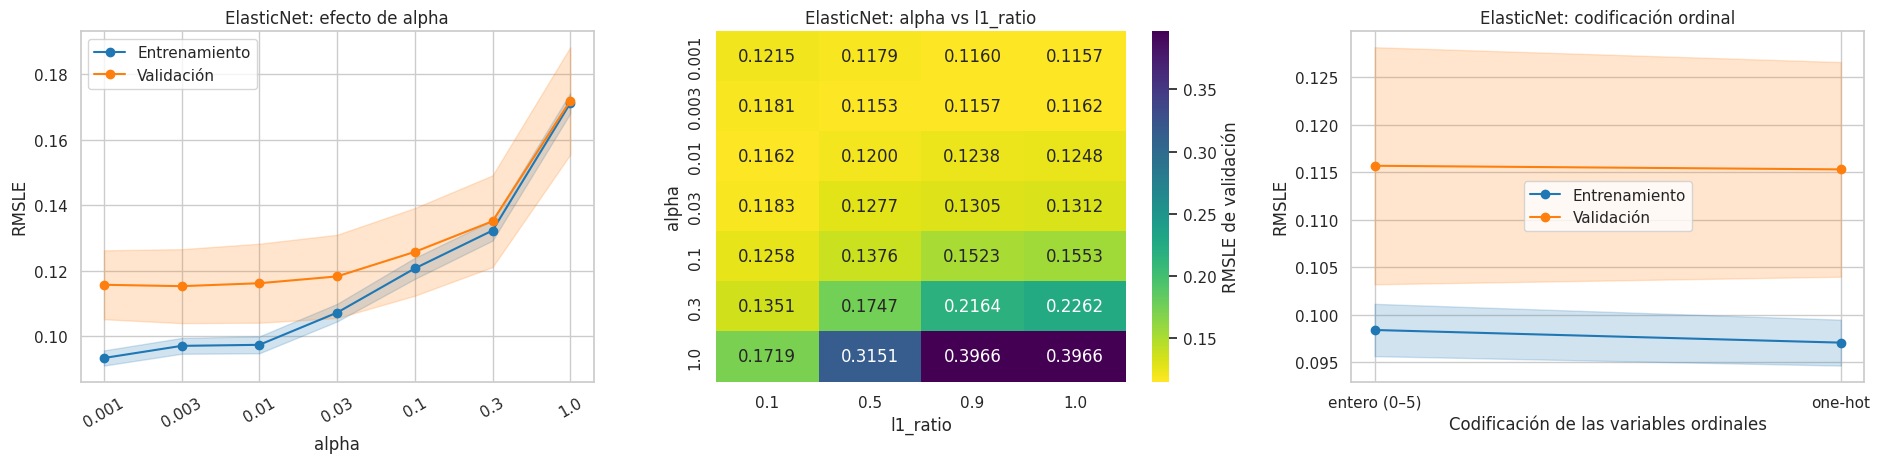

In [22]:
display(top_configs(res_en))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
curva(res_en, R + "alpha", ax[0], "ElasticNet: efecto de alpha")
mapa(res_en, R + "alpha", R + "l1_ratio", ax[1], "ElasticNet: alpha vs l1_ratio")
curva(res_en, "prep__ordinal_como_entero", ax[2], "ElasticNet: codificación ordinal")
ax[2].set_xticklabels(["one-hot" if t.get_text() == "False" else "entero (0–5)" for t in ax[2].get_xticklabels()], rotation=0)
ax[2].set_xlabel("Codificación de las variables ordinales")
guardar("07_elasticnet")

Fila final del modelo (train, validación y test con intervalos de confianza).

In [23]:
idx = res_en["rank_test_RMSLE"].idxmin()
RESULTADOS["ElasticNet"] = fila_test(pipe_en, fila_cv(res_en, idx, "ElasticNet"))
mostrar([RESULTADOS["ElasticNet"]]).T

modelo,ElasticNet
RMSLE train,0.0971 ± 0.0034
RMSLE val,0.1153 ± 0.0157
RMSE train,"17,390 ± 566"
RMSE val,"21,986 ± 5,282"
MAE train,"11,828 ± 224"
MAE val,"14,050 ± 1,577"
R2 train,0.952 ± 0.004
R2 val,0.920 ± 0.035


## 7. Modelo no paramétrico: Árbol de decisión
No supone una forma funcional: divide los datos con reglas "si… entonces…" y cada hoja predice el promedio de sus casas. No necesita escalado.
- `max_depth`: profundidad máxima (más profundo = más complejo).
- `min_samples_leaf`: mínimo de casas por hoja (más alto = árbol más podado).

Búsqueda en malla (6 × 4 = 24 combinaciones).

In [24]:
res_dt, pipe_dt, best_dt = buscar(
    "arbol", DecisionTreeRegressor(random_state=SEED), MALLAS["Árbol de decisión"], escalar=False)
print("Mejores hiperparámetros:", best_dt)

[arbol] 24 combinaciones en 0.3 min
Mejores hiperparámetros: {'modelo__regressor__max_depth': 7, 'modelo__regressor__min_samples_leaf': 5}


Tabla de las 5 mejores combinaciones, efecto de la profundidad y mapa de calor `max_depth` × `min_samples_leaf`.

,max_depth,min_samples_leaf,RMSLE train,RMSLE val (± desv.),R² val
puesto,,,,,
1,7,5,0.1183,0.1937 ± 0.0118,0.785
2,10,5,0.0988,0.1961 ± 0.0131,0.781
3,None,5,0.0968,0.1965 ± 0.0139,0.780
4,15,5,0.0968,0.1965 ± 0.0139,0.780
5,15,10,0.1297,0.1981 ± 0.0099,0.751


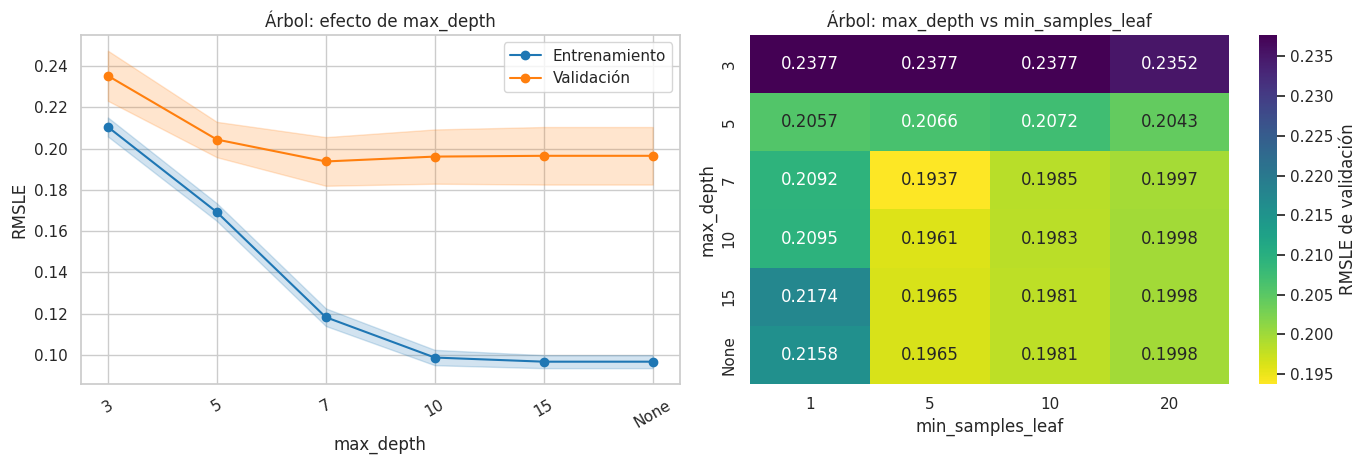

In [25]:
display(top_configs(res_dt))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
curva(res_dt, R + "max_depth", ax[0], "Árbol: efecto de max_depth", orden=[3, 5, 7, 10, 15, None])
mapa(res_dt, R + "max_depth", R + "min_samples_leaf", ax[1], "Árbol: max_depth vs min_samples_leaf")
guardar("08_arbol")

Fila final del modelo.

In [26]:
idx = res_dt["rank_test_RMSLE"].idxmin()
RESULTADOS["Árbol de decisión"] = fila_test(pipe_dt, fila_cv(res_dt, idx, "Árbol de decisión"))
mostrar([RESULTADOS["Árbol de decisión"]]).T

modelo,Árbol de decisión
RMSLE train,0.1183 ± 0.0059
RMSLE val,0.1937 ± 0.0164
RMSE train,"23,033 ± 1,510"
RMSE val,"36,033 ± 2,277"
MAE train,"15,288 ± 790"
MAE val,"24,819 ± 1,304"
R2 train,0.916 ± 0.008
R2 val,0.785 ± 0.059


## 8. Ensamble por bagging: Random Forest
Entrena muchos árboles, cada uno con una muestra *bootstrap* de las casas y un subconjunto aleatorio de variables en cada corte, y promedia sus predicciones. Reduce la varianza del árbol individual.
- `n_estimators`: número de árboles.
- `max_features`: fracción de variables candidatas en cada corte (`sqrt` = raíz del total).
- `min_samples_leaf`: mínimo de casas por hoja.

Búsqueda en malla (2 × 3 × 3 = 18 combinaciones).

In [27]:
res_rf, pipe_rf, best_rf = buscar(
    "random_forest", RandomForestRegressor(random_state=SEED, n_jobs=1),
    MALLAS["Random Forest"], escalar=False)
print("Mejores hiperparámetros:", best_rf)

[random_forest] 18 combinaciones en 5.6 min
Mejores hiperparámetros: {'modelo__regressor__max_features': 0.33, 'modelo__regressor__min_samples_leaf': 1, 'modelo__regressor__n_estimators': 200}


Tabla de las 5 mejores combinaciones, efecto de `max_features` y mapa de calor `max_features` × `min_samples_leaf`.

,max_features,min_samples_leaf,n_estimators,RMSLE train,RMSLE val (± desv.),R² val
puesto,,,,,,
1,0.33,1,200,0.0506,0.1355 ± 0.0160,0.878
2,0.33,1,500,0.0502,0.1356 ± 0.0157,0.879
3,0.33,3,200,0.0774,0.1378 ± 0.0154,0.871
4,0.33,3,500,0.0772,0.1380 ± 0.0152,0.871
5,0.33,5,500,0.0957,0.1413 ± 0.0150,0.861


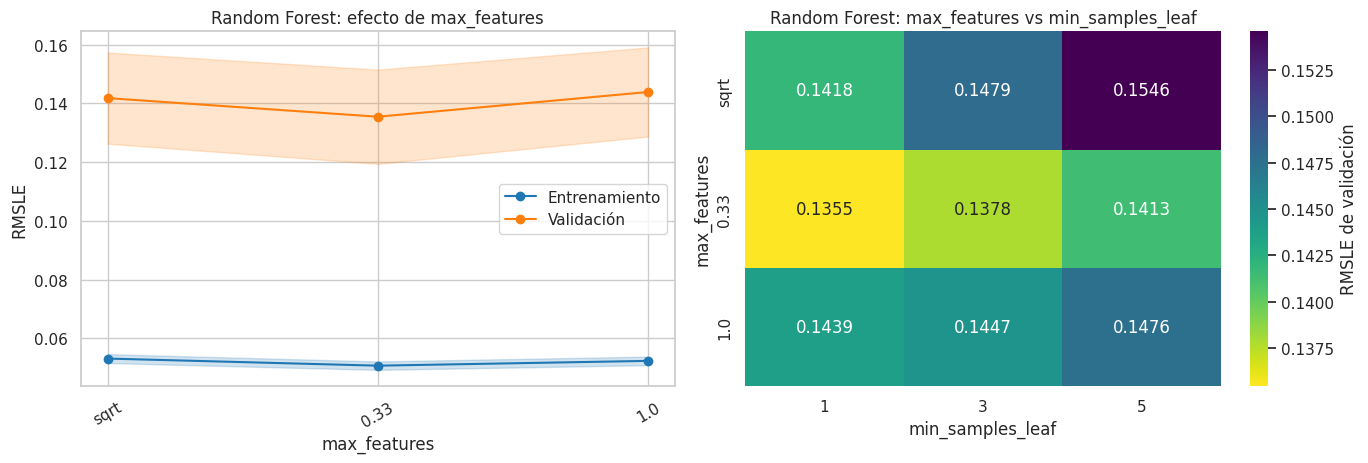

In [28]:
display(top_configs(res_rf))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
curva(res_rf, R + "max_features", ax[0], "Random Forest: efecto de max_features")
mapa(res_rf, R + "max_features", R + "min_samples_leaf", ax[1], "Random Forest: max_features vs min_samples_leaf")
guardar("09_random_forest")

Fila final del modelo.

In [29]:
idx = res_rf["rank_test_RMSLE"].idxmin()
RESULTADOS["Random Forest"] = fila_test(pipe_rf, fila_cv(res_rf, idx, "Random Forest"))
mostrar([RESULTADOS["Random Forest"]]).T

modelo,Random Forest
RMSLE train,0.0506 ± 0.0020
RMSLE val,0.1355 ± 0.0223
RMSE train,"10,998 ± 403"
RMSE val,"27,549 ± 4,447"
MAE train,"6,305 ± 117"
MAE val,"16,673 ± 2,096"
R2 train,0.981 ± 0.002
R2 val,0.878 ± 0.018


## 9. Ensamble por boosting: XGBoost
Entrena árboles pequeños **en secuencia**: cada uno corrige los errores de los anteriores. Reduce el sesgo.
- `n_estimators`: número de árboles.
- `learning_rate`: cuánto aporta cada árbol (más bajo = más estable, pero necesita más árboles).
- `max_depth`: profundidad de cada árbol.
- `subsample`: fracción de casas que ve cada árbol (menor que 1 regulariza).

Búsqueda en malla (3 × 3 × 4 × 2 = 72 combinaciones). Es la búsqueda más larga.

In [30]:
res_xgb, pipe_xgb, best_xgb = buscar(
    "xgboost", XGBRegressor(random_state=SEED, n_jobs=1, tree_method="hist"),
    MALLAS["XGBoost"], escalar=False)
print("Mejores hiperparámetros:", best_xgb)

[xgboost] 72 combinaciones en 12.0 min
Mejores hiperparámetros: {'modelo__regressor__learning_rate': 0.05, 'modelo__regressor__max_depth': 2, 'modelo__regressor__n_estimators': 1000, 'modelo__regressor__subsample': 0.7}


Tabla de las 5 mejores combinaciones, efecto del número de árboles y mapa de calor `learning_rate` × `max_depth`.

,learning_rate,max_depth,n_estimators,subsample,RMSLE train,RMSLE val (± desv.),R² val
puesto,,,,,,,
1,0.05,2,1000,0.7,0.0567,0.1221 ± 0.0082,0.910
2,0.01,3,2000,0.7,0.0545,0.1222 ± 0.0091,0.907
3,0.05,4,500,0.7,0.0276,0.1224 ± 0.0090,0.906
4,0.05,4,1000,0.7,0.0104,0.1224 ± 0.0086,0.906
5,0.05,4,2000,0.7,0.0021,0.1225 ± 0.0084,0.906


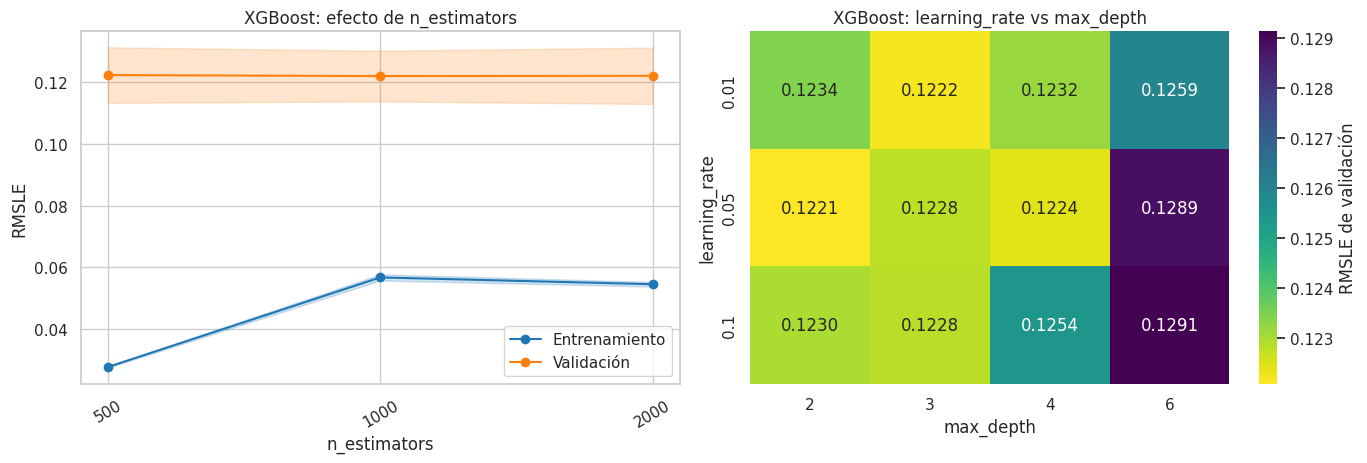

In [31]:
display(top_configs(res_xgb))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
curva(res_xgb, R + "n_estimators", ax[0], "XGBoost: efecto de n_estimators")
mapa(res_xgb, R + "learning_rate", R + "max_depth", ax[1], "XGBoost: learning_rate vs max_depth")
guardar("10_xgboost")

Fila final del modelo.

In [32]:
idx = res_xgb["rank_test_RMSLE"].idxmin()
RESULTADOS["XGBoost"] = fila_test(pipe_xgb, fila_cv(res_xgb, idx, "XGBoost"))
mostrar([RESULTADOS["XGBoost"]]).T

modelo,XGBoost
RMSLE train,0.0567 ± 0.0014
RMSLE val,0.1221 ± 0.0114
RMSE train,"10,430 ± 291"
RMSE val,"23,654 ± 3,764"
MAE train,"7,504 ± 145"
MAE val,"15,151 ± 1,371"
R2 train,0.983 ± 0.001
R2 val,0.910 ± 0.017


## 10. Red neuronal artificial: MLPRegressor
Perceptrón multicapa con activación ReLU, optimizador Adam y **parada temprana** (`early_stopping=True`: aparta el 10 % de cada pliegue de entrenamiento y se detiene cuando el error deja de mejorar, lo que evita el sobreajuste).
- `hidden_layer_sizes`: arquitectura (número de capas ocultas y de neuronas).
- `alpha`: regularización L2 de los pesos.
- `learning_rate_init`: tamaño del paso del descenso por gradiente.

Búsqueda en malla (5 × 5 × 2 = 50 combinaciones).

In [33]:
res_mlp, pipe_mlp, best_mlp = buscar(
    "mlp", MLPRegressor(activation="relu", solver="adam", early_stopping=True,
                        max_iter=2000, random_state=SEED),
    MALLAS["Red neuronal (MLP)"])
print("Mejores hiperparámetros:", best_mlp)

[mlp] 50 combinaciones en 1.9 min
Mejores hiperparámetros: {'modelo__regressor__alpha': 3.0, 'modelo__regressor__hidden_layer_sizes': (128,), 'modelo__regressor__learning_rate_init': 0.001}


Tabla de las 5 mejores combinaciones, efecto de `alpha` y mapa de calor arquitectura × `alpha`.

,alpha,hidden_layer_sizes,learning_rate_init,RMSLE train,RMSLE val (± desv.),R² val
puesto,,,,,,
1,3.0,"(128,)",0.001,0.0882,0.1178 ± 0.0159,0.916
2,3.0,"(64,)",0.001,0.0905,0.1191 ± 0.0124,0.911
3,1.0,"(128,)",0.001,0.0741,0.1198 ± 0.0151,0.918
4,1.0,"(128,)",0.01,0.0904,0.1199 ± 0.0131,0.916
5,3.0,"(128, 64)",0.001,0.0967,0.1204 ± 0.0142,0.905


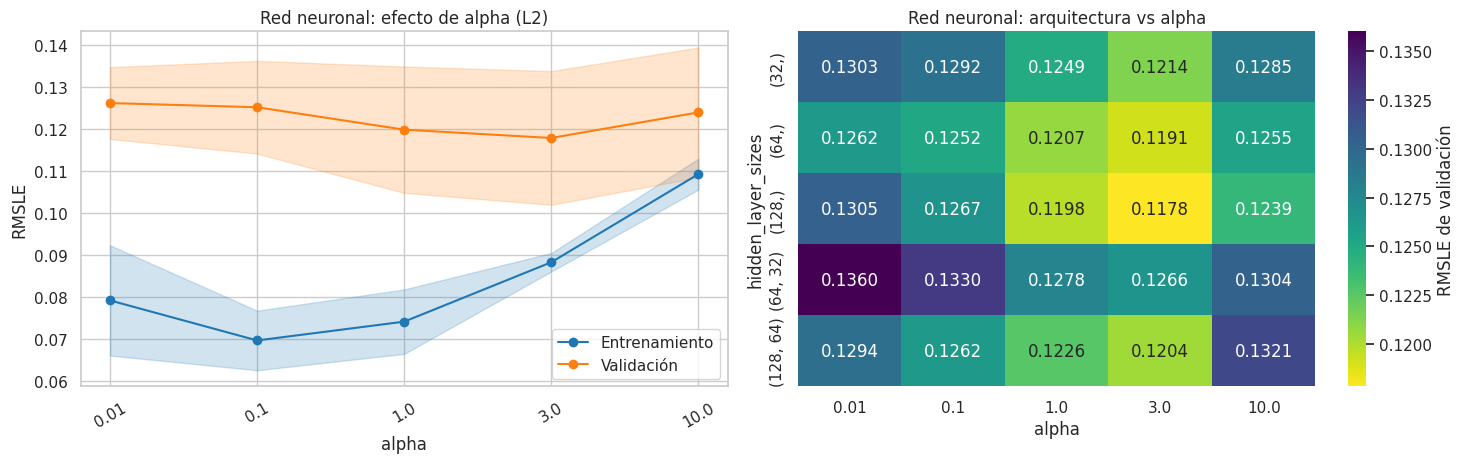

In [34]:
display(top_configs(res_mlp))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
curva(res_mlp, R + "alpha", ax[0], "Red neuronal: efecto de alpha (L2)")
mapa(res_mlp, R + "hidden_layer_sizes", R + "alpha", ax[1], "Red neuronal: arquitectura vs alpha")
guardar("11_red_neuronal")

Fila final del modelo.

In [35]:
idx = res_mlp["rank_test_RMSLE"].idxmin()
RESULTADOS["Red neuronal (MLP)"] = fila_test(pipe_mlp, fila_cv(res_mlp, idx, "Red neuronal (MLP)"))
mostrar([RESULTADOS["Red neuronal (MLP)"]]).T

modelo,Red neuronal (MLP)
RMSLE train,0.0882 ± 0.0031
RMSLE val,0.1178 ± 0.0221
RMSE train,"16,526 ± 1,166"
RMSE val,"22,604 ± 4,384"
MAE train,"10,759 ± 337"
MAE val,"14,678 ± 2,247"
R2 train,0.956 ± 0.005
R2 val,0.916 ± 0.031


## 11. Máquina de vectores de soporte: SVR con kernel RBF
Busca una función que deje la mayoría de las casas dentro de un "tubo" de ancho ε alrededor de la predicción; solo penaliza los errores fuera del tubo.
- `C`: penalización de los errores (más alto = menos regularización).
- `gamma`: alcance de cada vector de soporte (más alto = función más "ondulada").
- `epsilon`: ancho del tubo (en unidades del objetivo estandarizado).

Búsqueda en malla (4 × 4 × 3 = 48 combinaciones).

In [36]:
res_svr, pipe_svr, best_svr = buscar("svr", SVR(kernel="rbf"), MALLAS["SVR (RBF)"])
print("Mejores hiperparámetros:", best_svr)

[svr] 48 combinaciones en 2.4 min
Mejores hiperparámetros: {'modelo__regressor__C': 100, 'modelo__regressor__epsilon': 0.1, 'modelo__regressor__gamma': 0.0001}


Tabla de las 5 mejores combinaciones, mapa de calor `C` × `gamma` y efecto de `epsilon`.

,C,epsilon,gamma,RMSLE train,RMSLE val (± desv.),R² val
puesto,,,,,,
1,100,0.1,0.0001,0.0992,0.1147 ± 0.0152,0.924
2,10,0.01,0.001,0.0910,0.1155 ± 0.0136,0.913
3,10,0.05,0.001,0.0904,0.1155 ± 0.0135,0.912
4,10,0.1,0.001,0.0906,0.1157 ± 0.0136,0.913
5,100,0.05,0.0001,0.0998,0.1158 ± 0.0156,0.920


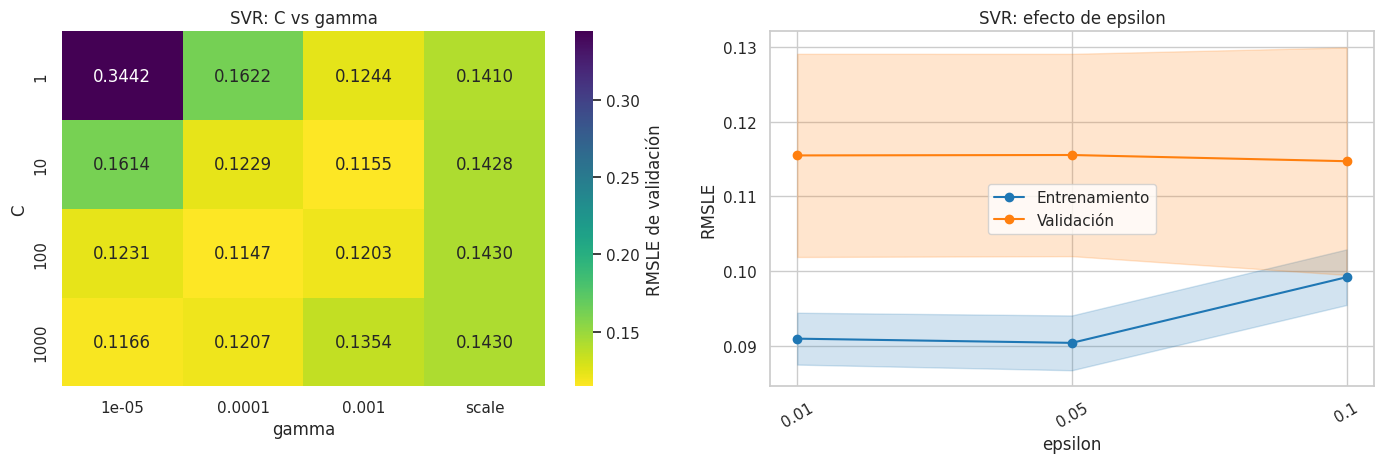

In [37]:
display(top_configs(res_svr))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
mapa(res_svr, R + "C", R + "gamma", ax[0], "SVR: C vs gamma")
curva(res_svr, R + "epsilon", ax[1], "SVR: efecto de epsilon")
guardar("12_svr")

Fila final del modelo.

In [38]:
idx = res_svr["rank_test_RMSLE"].idxmin()
RESULTADOS["SVR (RBF)"] = fila_test(pipe_svr, fila_cv(res_svr, idx, "SVR (RBF)"))
mostrar([RESULTADOS["SVR (RBF)"]]).T

modelo,SVR (RBF)
RMSLE train,0.0992 ± 0.0052
RMSLE val,0.1147 ± 0.0211
RMSE train,"17,137 ± 780"
RMSE val,"21,489 ± 4,945"
MAE train,"11,093 ± 360"
MAE val,"13,779 ± 1,795"
R2 train,0.953 ± 0.005
R2 val,0.924 ± 0.033


## 12. Comparación de los seis modelos
*Ahora se muestra la tabla final con todas las métricas en **entrenamiento, validación y test** (media ± intervalo de confianza del 95 %), ordenada de mejor a peor RMSLE de validación. Se guarda en `results/tabla_final_modelos.csv`.

In [39]:
def mostrar_final(filas):
    tabla = pd.DataFrame(filas).set_index("modelo").sort_values("RMSLE_val")
    salida = pd.DataFrame(index=tabla.index)
    formatos = {"RMSLE": "{:.4f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}"}
    for m, f in formatos.items():
        for fase in ["train", "val", "test"]:
            salida[(m, fase)] = [f"{f.format(a)} ± {f.format(b)}"
                                 for a, b in zip(tabla[f"{m}_{fase}"], tabla[f"{m}_{fase}_IC"])]
    salida.columns = pd.MultiIndex.from_tuples(salida.columns, names=["Métrica", "Conjunto"])
    return tabla, salida

tabla_final, tabla_bonita = mostrar_final(list(RESULTADOS.values()))
tabla_final.to_csv("results/tabla_final_modelos.csv")
tabla_bonita

Métrica                       RMSLE                                    \
Conjunto                      train              val             test   
modelo                                                                  
SVR (RBF)           0.0992 ± 0.0052  0.1147 ± 0.0211  0.1111 ± 0.0169   
ElasticNet          0.0971 ± 0.0034  0.1153 ± 0.0157  0.1099 ± 0.0135   
Red neuronal (MLP)  0.0882 ± 0.0031  0.1178 ± 0.0221  0.1145 ± 0.0167   
XGBoost             0.0567 ± 0.0014  0.1221 ± 0.0114  0.1061 ± 0.0130   
Random Forest       0.0506 ± 0.0020  0.1355 ± 0.0223  0.1268 ± 0.0217   
Árbol de decisión   0.1183 ± 0.0059  0.1937 ± 0.0164  0.1641 ± 0.0197   

Métrica                       RMSE                                  \
Conjunto                     train             val            test   
modelo                                                               
SVR (RBF)             17,137 ± 780  21,489 ± 4,945  20,056 ± 3,385   
ElasticNet            17,390 ± 566  21,986 ± 5,282  20,584 ± 3,801   
Red neuronal (MLP)  16,526 ± 1,166  22,604 ± 4,384  22,057 ± 4,292   
XGBoost               10,430 ± 291  23,654 ± 3,764  19,948 ± 3,502   
Random Forest         10,998 ± 403  27,549 ± 4,447  24,256 ± 5,687   
Árbol de decisión   23,033 ± 1,510  36,033 ± 2,277  31,127 ± 5,099   

Métrica                      MAE                                  \
Conjunto                   train             val            test   
modelo                                                             
SVR (RBF)           11,093 ± 360  13,779 ± 1,795  13,685 ± 1,608   
ElasticNet          11,828 ± 224  14,050 ± 1,577  13,791 ± 1,682   
Red neuronal (MLP)  10,759 ± 337  14,678 ± 2,247  14,349 ± 1,919   
XGBoost              7,504 ± 145  15,151 ± 1,371  13,388 ± 1,674   
Random Forest        6,305 ± 117  16,673 ± 2,096  14,931 ± 2,204   
Árbol de decisión   15,288 ± 790  24,819 ± 1,304  21,354 ± 2,615   

Métrica                        R2                                
Conjunto                    train            val           test  
modelo                                                           
SVR (RBF)           0.953 ± 0.005  0.924 ± 0.033  0.937 ± 0.019  
ElasticNet          0.952 ± 0.004  0.920 ± 0.035  0.934 ± 0.021  
Red neuronal (MLP)  0.956 ± 0.005  0.916 ± 0.031  0.924 ± 0.019  
XGBoost             0.983 ± 0.001  0.910 ± 0.017  0.938 ± 0.021  
Random Forest       0.981 ± 0.002  0.878 ± 0.018  0.908 ± 0.022  
Árbol de decisión   0.916 ± 0.008  0.785 ± 0.059  0.849 ± 0.044

En el siguiente bloque se muestra la gráfica comparativa del RMSLE de cada modelo en entrenamiento, validación y test, con barras de error (intervalo de confianza del 95 %).

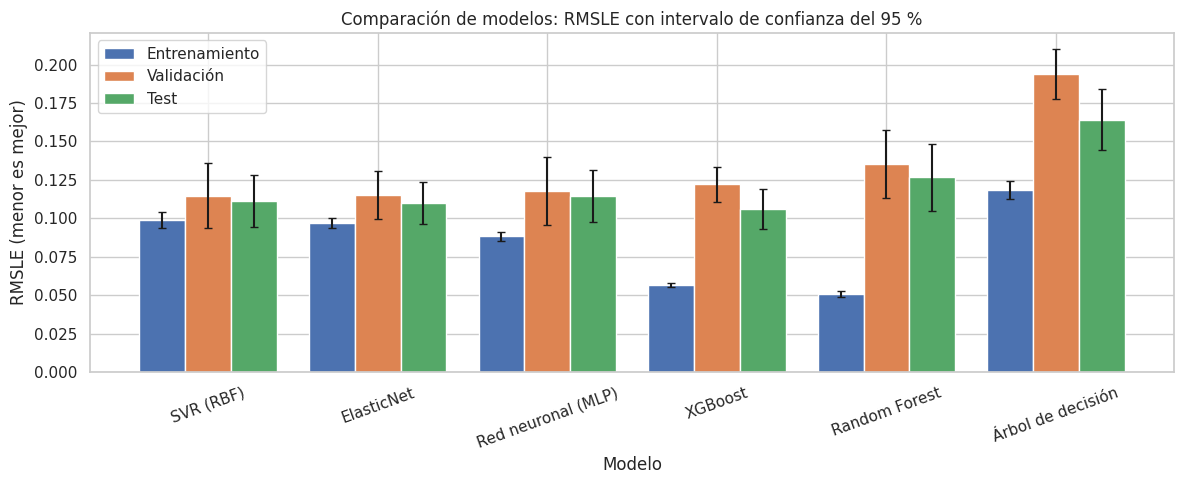

In [40]:
orden = tabla_final.index
x = np.arange(len(orden))
ancho = 0.27
fig, ax = plt.subplots(figsize=(12, 5))
for i, (fase, etiqueta) in enumerate([("train", "Entrenamiento"), ("val", "Validación"), ("test", "Test")]):
    ax.bar(x + (i - 1) * ancho, tabla_final[f"RMSLE_{fase}"], ancho,
           yerr=tabla_final[f"RMSLE_{fase}_IC"], capsize=3, label=etiqueta)
ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=20)
ax.set_xlabel("Modelo")
ax.set_ylabel("RMSLE (menor es mejor)")
ax.set_title("Comparación de modelos: RMSLE con intervalo de confianza del 95 %")
ax.legend()
guardar("13_comparacion_modelos")

Selección de los **2 mejores modelos** según el RMSLE de **validación** (no de test, para que el test siga siendo una evaluación honesta). Estos dos modelos son los que se usan en la Fase 3 (PCA y UMAP). Se guardan sus nombres y mejores hiperparámetros.

In [41]:
PIPES = {"ElasticNet": pipe_en, "Árbol de decisión": pipe_dt, "Random Forest": pipe_rf,
         "XGBoost": pipe_xgb, "Red neuronal (MLP)": pipe_mlp, "SVR (RBF)": pipe_svr}

top2 = tabla_final.index[:2].tolist()
print("Los 2 mejores modelos (por RMSLE de validación):")
for m in top2:
    print(f"  - {m}: RMSLE val = {tabla_final.loc[m, 'RMSLE_val']:.4f} | "
          f"RMSLE test = {tabla_final.loc[m, 'RMSLE_test']:.4f}")
joblib.dump({m: PIPES[m].get_params() for m in top2}, "results/top2_modelos.pkl")

Los 2 mejores modelos (por RMSLE de validación):
  - SVR (RBF): RMSLE val = 0.1147 | RMSLE test = 0.1111
  - ElasticNet: RMSLE val = 0.1153 | RMSLE test = 0.1099


['results/top2_modelos.pkl']

Gráfica de precio real vs precio predicho en **test** para los dos mejores modelos. Si el modelo fuera perfecto, todos los puntos estarían sobre la línea diagonal.

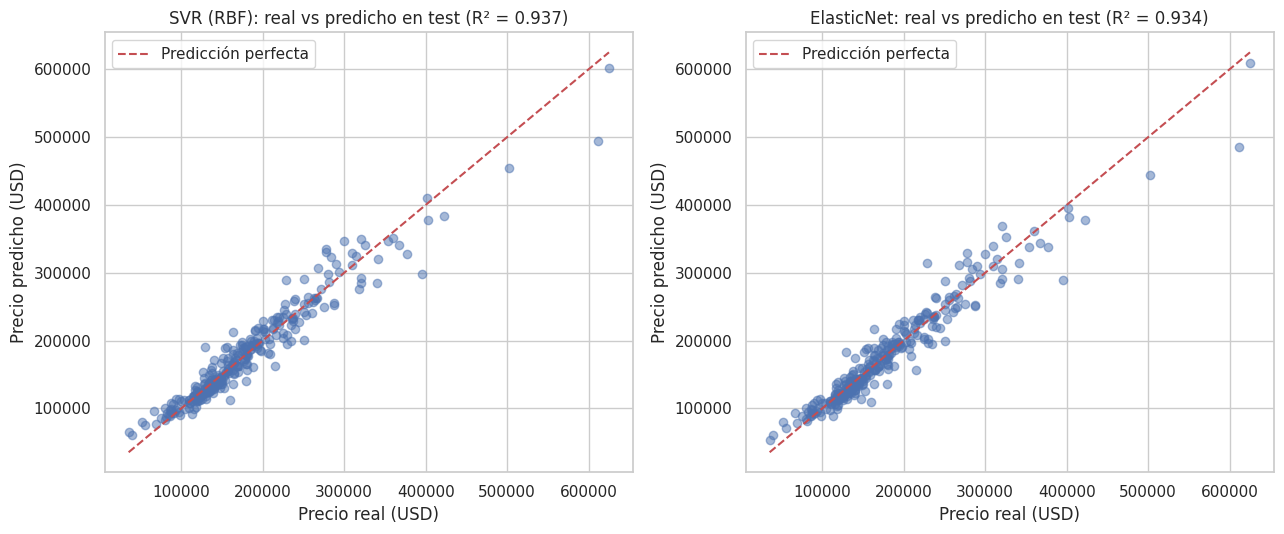

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, m in zip(ax, top2):
    pred = PIPES[m].predict(X_test)
    a.scatter(y_test, pred, alpha=0.5)
    lim = [y_test.min(), y_test.max()]
    a.plot(lim, lim, "r--", label="Predicción perfecta")
    a.set_xlabel("Precio real (USD)")
    a.set_ylabel("Precio predicho (USD)")
    a.set_title(f"{m}: real vs predicho en test (R² = {r2_score(y_test, pred):.3f})")
    a.legend()
guardar("14_real_vs_predicho")

### Consideraciones importantes de los resultados
- **Sobreajuste:** comparar las columnas *train* y *val* de la tabla final. Una diferencia grande (p. ej. el árbol sin límite de profundidad) indica que el modelo memoriza.
- **Validación vs test:** si el RMSLE de test cae dentro del intervalo de validación, la estimación de la validación cruzada fue confiable.
- **Variables de calidad:** `OverallQual` y `ExterQual` están muy correlacionadas con el precio. No es fuga de información (se conocen al momento de la venta), pero hace que el problema sea más fácil de lo que parece; hay que mencionarlo en la discusión del informe.

